# 퍼셉트론 실습: AND 게이트

이번 실습에서는 가중치와 바이어스가 정해진 퍼셉트론 하나로 출력 y를 직접 계산해 보겠습니다.

```
  b (-1.5) ──┐
             │
  x1 ── w1(1) ┼──→ ( Σ ) ──→ y
             │
  x2 ── w2(1) ┘
```

- 가중치: w1 = 1, w2 = 1
- 바이어스: b = -1.5
- 계산식: z = w1·x1 + w2·x2 + b
- 출력: z > 0 이면 y = 1, 아니면 y = 0 (계단 함수)

1. 필요한 라이브러리 불러오기
2. 가중치와 바이어스 정하기
3. 계단 함수 만들기
4. 입력 하나로 y 계산하기
5. 모든 입력 조합으로 y 계산하기
6. 결정 경계 그리기
7. 바이어스를 -0.5로 바꾸면?

## 1. 필요한 라이브러리 불러오기

`numpy`는 계산에, `matplotlib`은 그래프를 그리는 데 사용합니다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2. 가중치와 바이어스 정하기

딥러닝에서는 이 값을 학습으로 찾지만, 여기서는 사람이 직접 정해 줍니다.

- 가중치: 입력 중 어떤 입력을 더 중요하게 여길 것인가
- 바이어스: 출력이 1이 되기 위한 문턱(기준)을 조정하는 값

In [2]:
w = np.array([1.0, 1.0])   # w1, w2
b = -1.5                   # 바이어스

print("가중치 w:", w)
print("바이어스 b:", b)

가중치 w: [1. 1.]
바이어스 b: -1.5


## 3. 계단 함수 만들기

활성화 함수로 계단 함수를 사용합니다. 합 z가 0보다 크면 1, 아니면 0을 출력합니다.

In [3]:
def step(z):
    return 1 if z > 0 else 0

print(step(0.5))    # 1
print(step(-0.5))   # 0

1
0


## 4. 입력 하나로 y 계산하기

x1 = 1, x2 = 1을 넣어서 직접 계산해 보겠습니다.

z = 1×1 + 1×1 + (-1.5) = 0.5 이므로 y = 1이 나와야 합니다.

In [4]:
x = np.array([1, 1])   # x1, x2

z = np.sum(w * x) + b  # 가중합 + 바이어스
y = step(z)

print("입력 x:", x)
print("z =", z)
print("y =", y)

입력 x: [1 1]
z = 0.5
y = 1


## 5. 모든 입력 조합으로 y 계산하기

입력 4가지 조합을 모두 넣어 보면 두 입력이 모두 1일 때만 y = 1이 됩니다. 즉 이 퍼셉트론은 **AND 게이트**입니다.

In [5]:
inputs = [(0, 0), (0, 1), (1, 0), (1, 1)]

print(" x1  x2 |    z  | y")
print("--------+-------+---")
for x1, x2 in inputs:
    z = w[0] * x1 + w[1] * x2 + b
    y = step(z)
    print(f" {x1:>2}  {x2:>2} | {z:5.1f} | {y}")

 x1  x2 |    z  | y
--------+-------+---
  0   0 |  -1.5 | 0
  0   1 |  -0.5 | 0
  1   0 |  -0.5 | 0
  1   1 |   0.5 | 1


## 6. 결정 경계 그리기

z = 0이 되는 선, 즉 x1 + x2 - 1.5 = 0 (x2 = -x1 + 1.5)이 출력 0과 1을 나누는 기준선입니다.
이 선 위쪽에 있는 점만 y = 1로 분류됩니다.

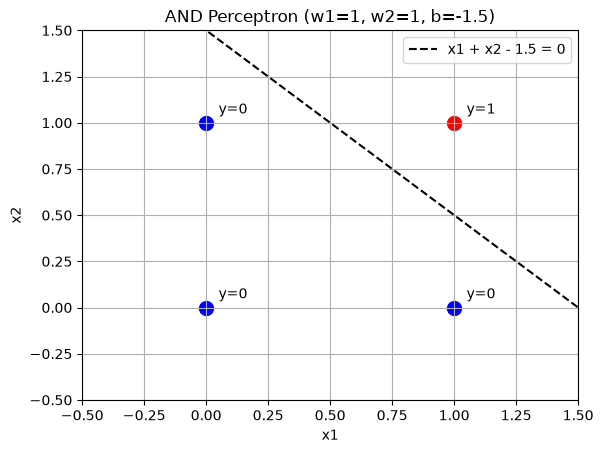

In [6]:
for x1, x2 in inputs:
    y = step(w[0] * x1 + w[1] * x2 + b)
    color = "red" if y == 1 else "blue"
    plt.scatter(x1, x2, color=color, s=100)
    plt.text(x1 + 0.05, x2 + 0.05, f"y={y}")

line_x = np.linspace(-0.5, 1.5, 100)
line_y = -(w[0] * line_x + b) / w[1]   # x2 = -x1 + 1.5
plt.plot(line_x, line_y, "k--", label="x1 + x2 - 1.5 = 0")

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("AND Perceptron (w1=1, w2=1, b=-1.5)")
plt.legend()
plt.grid(True)
plt.show()

## 7. 바이어스를 -0.5로 바꾸면?

가중치는 그대로 두고 바이어스만 -1.5 → -0.5로 바꿔 보겠습니다.

z = x1 + x2 - 0.5 이므로 입력 중 **하나만 1이어도** z = 0.5 > 0이 되어 y = 1이 됩니다.
즉 AND 게이트가 **OR 게이트**로 바뀝니다.

In [7]:
b2 = -0.5   # 바뀐 바이어스

print(" x1  x2 | b=-1.5 (AND) | b=-0.5 (OR)")
print("--------+--------------+------------")
for x1, x2 in inputs:
    y_and = step(w[0] * x1 + w[1] * x2 + b)
    y_or = step(w[0] * x1 + w[1] * x2 + b2)
    print(f" {x1:>2}  {x2:>2} |      {y_and}       |     {y_or}")

 x1  x2 | b=-1.5 (AND) | b=-0.5 (OR)
--------+--------------+------------
  0   0 |      0       |     0
  0   1 |      0       |     1
  1   0 |      0       |     1
  1   1 |      1       |     1


결정 경계도 함께 비교해 보겠습니다. 가중치가 같으므로 선의 **기울기는 같고**, 바이어스가 바뀐 만큼 선이 **아래로 평행이동**합니다.

- b = -1.5: x2 = -x1 + 1.5 → (1,1)만 선 위쪽
- b = -0.5: x2 = -x1 + 0.5 → (0,1), (1,0), (1,1)이 선 위쪽

바이어스가 클수록(0에 가까울수록) 문턱이 낮아져서 y = 1이 되기 쉬워집니다.

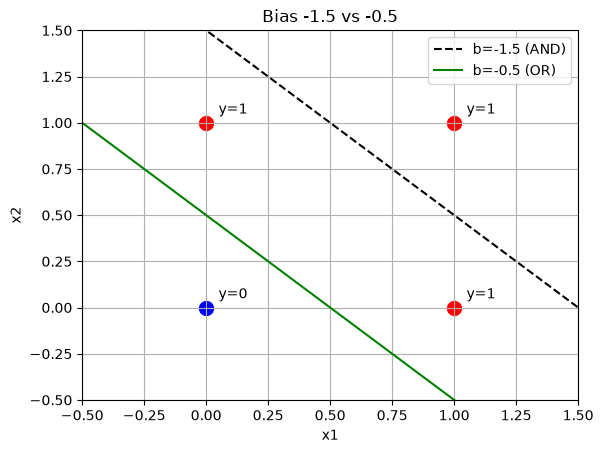

In [8]:
for x1, x2 in inputs:
    y = step(w[0] * x1 + w[1] * x2 + b2)
    color = "red" if y == 1 else "blue"
    plt.scatter(x1, x2, color=color, s=100)
    plt.text(x1 + 0.05, x2 + 0.05, f"y={y}")

plt.plot(line_x, -(w[0] * line_x + b) / w[1], "k--", label="b=-1.5 (AND)")
plt.plot(line_x, -(w[0] * line_x + b2) / w[1], "g-", label="b=-0.5 (OR)")

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Bias -1.5 vs -0.5")
plt.legend()
plt.grid(True)
plt.show()

## 정리

- 퍼셉트론은 입력에 가중치를 곱해 더하고 바이어스를 더한 뒤, 활성화 함수로 출력을 정합니다.
- w1 = 1, w2 = 1, b = -1.5이면 두 입력이 모두 1일 때만 합이 0을 넘으므로 AND 게이트가 됩니다.
- 바이어스를 -0.5로 바꾸면 입력 하나만 1이어도 0을 넘으므로 OR 게이트가 됩니다.
- 딥러닝(예: Wine 분류)에서는 이런 퍼셉트론을 여러 층으로 쌓고, w와 b를 사람이 정하지 않고 학습으로 찾습니다.